In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/mlp-jan-2026-kaggle-assignment-2/sample_submission.csv
/kaggle/input/competitions/mlp-jan-2026-kaggle-assignment-2/train.csv
/kaggle/input/competitions/mlp-jan-2026-kaggle-assignment-2/test.csv


In [2]:
df=pd.read_csv('/kaggle/input/competitions/mlp-jan-2026-kaggle-assignment-2/train.csv')
df_test=pd.read_csv('/kaggle/input/competitions/mlp-jan-2026-kaggle-assignment-2/test.csv')
df.describe()

,ID,mushroom_id,number_of_bruises,ring-number
count,7000.000000,7000.000000,7000.000000,6964.000000
mean,3500.500000,3850.617714,5.459571,1.080988
std,2020.870275,2208.389867,7.723528,0.272836
min,1.000000,0.000000,0.000000,1.000000
25%,1750.750000,2000.750000,0.000000,1.000000
50%,3500.500000,3755.500000,0.000000,1.000000
75%,5250.250000,5602.250000,11.000000,1.000000
max,7000.000000,8118.000000,24.000000,2.000000


DATATYPES

In [3]:
print(df.dtypes)

ID                            int64
mushroom_id                   int64
cap-shape                    object
cap-surface                  object
cap-color                    object
bruises                      object
number_of_bruises             int64
odor                         object
gill-attachment              object
gill-spacing                 object
gill-size                    object
gill-color                   object
stalk-shape                  object
stalk-root                   object
stalk-surface-above-ring     object
stalk-surface-below-ring     object
stalk-color-above-ring       object
stalk-color-below-ring       object
veil-type                    object
veil-color                   object
ring-number                 float64
ring-type                    object
spore-print-color            object
population                   object
habitat                      object
class                        object
dtype: object


FINDING NULL VALUES

In [4]:
print(df.isnull().sum())

ID                             0
mushroom_id                    0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
number_of_bruises              0
odor                        3236
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                   192
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                   36
ring-type                     36
spore-print-color              0
population                     0
habitat                        0
class                          0
dtype: int64


HANDLING MISSING VALUES

In [5]:
for col in ['odor', 'stalk-root', 'ring-type']:
    df[col] = df[col].fillna(df[col].mode()[0])
df['ring-number'] = df['ring-number'].fillna(df['ring-number'].median())

In [6]:
print(df.isnull().sum())

ID                          0
mushroom_id                 0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
number_of_bruises           0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
class                       0
dtype: int64


In [7]:
print(f"Before: {len(df)} rows")

df = df.drop_duplicates()

print(f"After:  {len(df)} rows")
print(f"Removed: {7000 - len(df)} duplicate rows")

Before: 7000 rows
After:  7000 rows
Removed: 0 duplicate rows


In [8]:
for col in ['number_of_bruises', 'ring-number']:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    df = df[(df[col] >= Q1 - 3*IQR) & (df[col] <= Q3 + 3*IQR)]
 
print(f"Train shape after cleaning: {df.shape}")

Train shape after cleaning: (6436, 26)


In [9]:
def Feat_engineer(df):
    df = df.copy()
    safe_odors = ['none', 'almond', 'anise']
    df['odor_dangerous']      = df['odor'].apply(lambda x: 0 if x in safe_odors else 1)
    df['has_bruises']         = (df['bruises'] == 'bruises').astype(int)
    df['stalk_color_match']   = (df['stalk-color-above-ring'] == df['stalk-color-below-ring']).astype(int)
    df['stalk_surface_match'] = (df['stalk-surface-above-ring'] == df['stalk-surface-below-ring']).astype(int)
    df['ring_present']        = (df['ring-type'] != 'none').astype(int)
    return df
 
train = Feat_engineer(df)
test  = Feat_engineer(df_test)

In [10]:
train.describe()


,ID,mushroom_id,number_of_bruises,ring-number,odor_dangerous,has_bruises,stalk_color_match,stalk_surface_match,ring_present
count,6436.000000,6436.000000,6436.000000,6436.0,6436.000000,6436.000000,6436.000000,6436.000000,6436.0
mean,3285.005594,3608.188471,5.410659,1.0,0.915475,0.437539,0.592293,0.780609,1.0
std,1951.981352,2114.796662,7.689362,0.0,0.278194,0.496122,0.491446,0.413866,0.0
min,1.000000,0.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,1.0
25%,1609.750000,1858.750000,0.000000,1.0,1.000000,0.000000,0.000000,1.000000,1.0
50%,3218.500000,3473.500000,0.000000,1.0,1.000000,0.000000,1.000000,1.000000,1.0
75%,4885.250000,5173.250000,11.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.0
max,7000.000000,8118.000000,24.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.0


In [11]:
test.describe()

,ID,mushroom_id,number_of_bruises,ring-number,odor_dangerous,has_bruises,stalk_color_match,stalk_surface_match,ring_present
count,1124.000000,1124.000000,1124.000000,1124.000000,1124.000000,1124.000000,1124.000000,1124.000000,1124.0
mean,562.500000,5374.823843,3.419039,1.032028,0.772242,0.266904,0.701068,0.722420,1.0
std,324.615157,2718.223965,6.766269,0.176154,0.419572,0.442539,0.457994,0.448004,0.0
min,1.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.0
25%,281.750000,5125.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.0
50%,562.500000,6441.500000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.0
75%,843.250000,7313.250000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
max,1124.000000,8123.000000,24.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.0


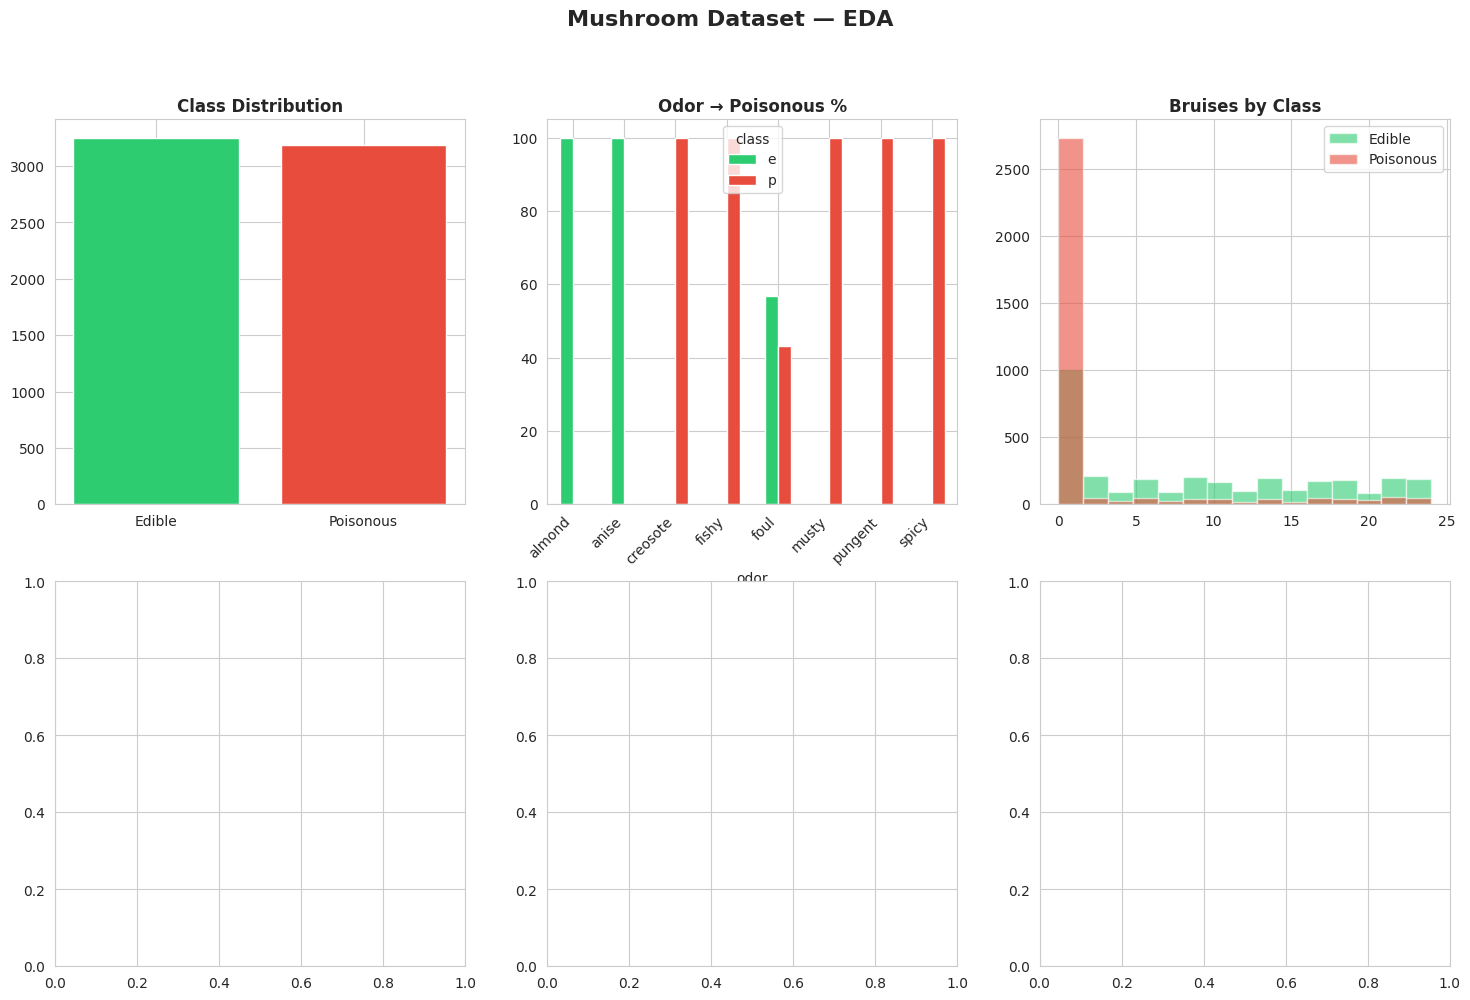

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Mushroom Dataset — EDA", fontsize=16, fontweight='bold')
 
# 1. Class distribution
ax = axes[0, 0]
counts = train['class'].value_counts()
ax.bar(['Edible', 'Poisonous'], counts.values, color=['#2ecc71', '#e74c3c'], edgecolor='white')
ax.set_title("Class Distribution", fontweight='bold')
 
# 2. Odor vs class
ax = axes[0, 1]
pd.crosstab(train['odor'], train['class'], normalize='index').mul(100).plot(
    kind='bar', ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='white')
ax.set_title("Odor → Poisonous %", fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
 
# 3. number_of_bruises by class
ax = axes[0, 2]
for cls, col in [('e', '#2ecc71'), ('p', '#e74c3c')]:
    ax.hist(train[train['class'] == cls]['number_of_bruises'], bins=15, alpha=0.6, color=col, label=cls)
ax.set_title("Bruises by Class", fontweight='bold')
ax.legend(['Edible', 'Poisonous'])

In [13]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

In [14]:

train['target'] = (train['class'] == 'p').astype(int)   # create target before encoding
 
test_ids = test['ID'].copy()
train.drop(columns=['ID', 'mushroom_id', 'class'], inplace=True)
test.drop(columns=['ID', 'mushroom_id'], inplace=True)
 
# Encode categoricals before splitting
cat_cols = [c for c in train.select_dtypes('object').columns if c != 'target']
train_enc = pd.get_dummies(train, columns=cat_cols)
test_enc  = pd.get_dummies(test,  columns=[c for c in cat_cols if c in test.columns])
 
X = train_enc.drop('target', axis=1)
y = train_enc['target']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
 
# Align test columns to train
X_test = test_enc.reindex(columns=X_train.columns, fill_value=0)
 
# Scale numeric — fit on train only
num_feats = ['number_of_bruises', 'ring-number']
scaler = StandardScaler()
X_train = X_train.copy(); X_val = X_val.copy(); X_test = X_test.copy()
X_train[num_feats] = scaler.fit_transform(X_train[num_feats])
X_val[num_feats]   = scaler.transform(X_val[num_feats])
X_test[num_feats]  = scaler.transform(X_test[num_feats])
 
print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

X_train: (5148, 97) | X_val: (1288, 97) | X_test: (1124, 97)


In [15]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Ridge Classifier':    RidgeClassifier(),
    'Lasso (LR-L1)':       LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=1000, random_state=42),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'KNN':                 KNeighborsClassifier(n_neighbors=5),
    'XGBoost':             XGBClassifier(eval_metric='logloss', random_state=42, verbosity=0),
}
 
results = {}; trained_models = {}
print("\n── Baseline Results ──")
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    acc = accuracy_score(y_val, preds)
    f1  = f1_score(y_val, preds)
    if hasattr(model, 'predict_proba'):
        auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    elif hasattr(model, 'decision_function'):
        auc = roc_auc_score(y_val, model.decision_function(X_val))
    else:
        auc = np.nan
    results[name] = {'Accuracy': round(acc, 4), 'F1': round(f1, 4), 'AUC': round(auc, 4)}
    trained_models[name] = model
    print(f"  {name:25s} Acc={acc:.4f}  F1={f1:.4f}  AUC={auc:.4f}")
 
results_df = pd.DataFrame(results).T.sort_values('F1', ascending=False)
top3 = results_df.head(3).index.tolist()
print(f"\nTop 3 for tuning: {top3}")


── Baseline Results ──
  Logistic Regression       Acc=1.0000  F1=1.0000  AUC=1.0000
  Ridge Classifier          Acc=1.0000  F1=1.0000  AUC=1.0000
  Lasso (LR-L1)             Acc=1.0000  F1=1.0000  AUC=1.0000
  Decision Tree             Acc=1.0000  F1=1.0000  AUC=1.0000
  Random Forest             Acc=1.0000  F1=1.0000  AUC=1.0000
  KNN                       Acc=1.0000  F1=1.0000  AUC=1.0000
  XGBoost                   Acc=1.0000  F1=1.0000  AUC=1.0000

Top 3 for tuning: ['Logistic Regression', 'Ridge Classifier', 'Lasso (LR-L1)']


In [16]:
param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10], 'solver': ['lbfgs', 'liblinear']},
    'Ridge Classifier':    {'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
    'Lasso (LR-L1)':       {'C': [0.01, 0.1, 1, 10], 'max_iter': [500, 1000, 2000]},
    'Decision Tree':       {'max_depth': [None, 5, 10, 20], 'min_samples_split': [2, 5, 10], 'criterion': ['gini', 'entropy']},
    'Random Forest':       {'n_estimators': [100, 200], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]},
    'KNN':                 {'n_neighbors': [3, 5, 7, 11], 'weights': ['uniform', 'distance']},
    'XGBoost':             {'n_estimators': [100, 200], 'max_depth': [3, 5, 7], 'learning_rate': [0.05, 0.1]},
}
estimator_map = {
    'Logistic Regression':  LogisticRegression(max_iter=1000, random_state=42),
    'Ridge Classifier':     RidgeClassifier(),
    'Lasso (LR-L1)':        LogisticRegression(penalty='l1', solver='liblinear', random_state=42),
    'Decision Tree':        DecisionTreeClassifier(random_state=42),
    'Random Forest':        RandomForestClassifier(random_state=42, n_jobs=-1),
    'KNN':                  KNeighborsClassifier(),
    'XGBoost':              XGBClassifier(eval_metric='logloss', random_state=42, verbosity=0),
}
 
print("\n── Hyperparameter Tuning ──")
tuned_models = {}
for name in top3:
    if name not in param_grids:
        print(f"  {name}: no grid defined, using baseline.")
        tuned_models[name] = trained_models[name]
        continue
    gs = GridSearchCV(estimator_map[name], param_grids[name], cv=5, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    print(f"  {name}: best={gs.best_params_}  CV-F1={gs.best_score_:.4f}")
    tuned_models[name] = gs.best_estimator_


── Hyperparameter Tuning ──
  Logistic Regression: best={'C': 1, 'solver': 'lbfgs'}  CV-F1=1.0000
  Ridge Classifier: best={'alpha': 0.01}  CV-F1=1.0000
  Lasso (LR-L1): best={'C': 0.1, 'max_iter': 500}  CV-F1=1.0000


In [17]:
print("\n── Final Comparison (Validation Set) ──")
all_eval = {**trained_models, **{n + ' (tuned)': m for n, m in tuned_models.items()}}
final_results = {}
for name, model in all_eval.items():
    preds = model.predict(X_val)
    acc = accuracy_score(y_val, preds)
    f1  = f1_score(y_val, preds)
    if hasattr(model, 'predict_proba'):
        auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
    elif hasattr(model, 'decision_function'):
        auc = roc_auc_score(y_val, model.decision_function(X_val))
    else:
        auc = np.nan
    final_results[name] = {'Accuracy': round(acc, 4), 'F1': round(f1, 4), 'AUC': round(auc, 4)}
 
final_df = pd.DataFrame(final_results).T.sort_values('F1', ascending=False)
print(final_df.to_string())
final_df.to_csv("model_results.csv")


── Final Comparison (Validation Set) ──
                             Accuracy   F1  AUC
Logistic Regression               1.0  1.0  1.0
Ridge Classifier                  1.0  1.0  1.0
Lasso (LR-L1)                     1.0  1.0  1.0
Decision Tree                     1.0  1.0  1.0
Random Forest                     1.0  1.0  1.0
KNN                               1.0  1.0  1.0
XGBoost                           1.0  1.0  1.0
Logistic Regression (tuned)       1.0  1.0  1.0
Ridge Classifier (tuned)          1.0  1.0  1.0
Lasso (LR-L1) (tuned)             1.0  1.0  1.0


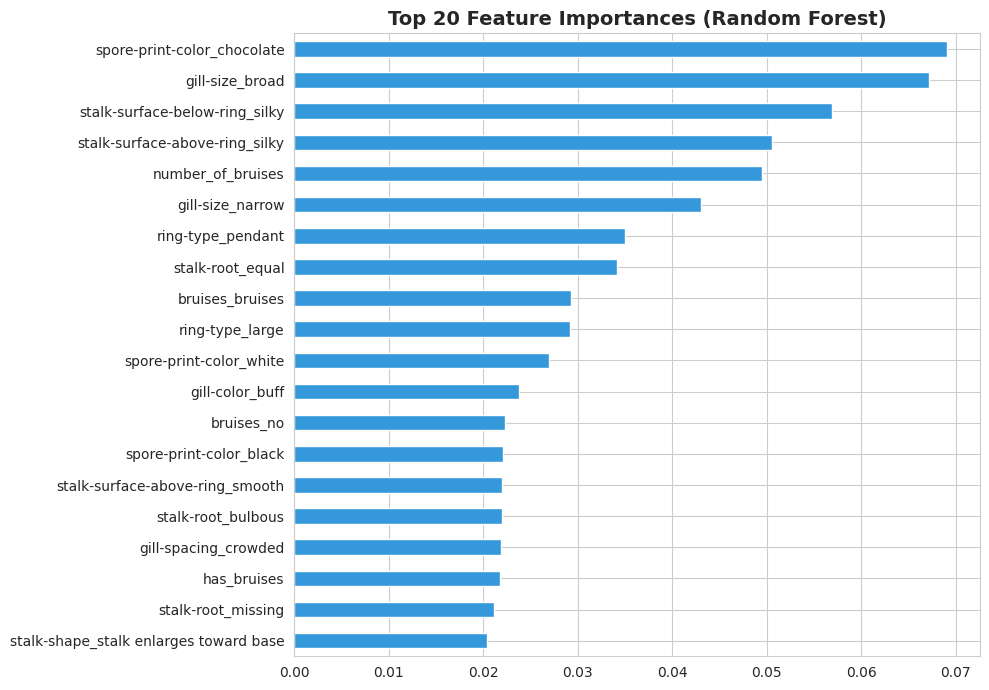

In [18]:
rf_model = tuned_models.get('Random Forest', trained_models.get('Random Forest'))
if rf_model and hasattr(rf_model, 'feature_importances_'):
    fi = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(20)
    fig, ax = plt.subplots(figsize=(10, 7))
    fi.sort_values().plot(kind='barh', ax=ax, color='#3498db', edgecolor='white')
    ax.set_title("Top 20 Feature Importances (Random Forest)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=150, bbox_inches='tight')
    plt.show()

In [19]:
# Reload raw test to rebuild submission cleanly
test_raw2  = pd.read_csv("/kaggle/input/competitions/mlp-jan-2026-kaggle-assignment-2/test.csv")
train_raw = pd.read_csv("/kaggle/input/competitions/mlp-jan-2026-kaggle-assignment-2/train.csv")

test2 = test_raw2.copy()
test2_ids = test2['ID'].copy()
 
for col in ['stalk-root', 'ring-type']:
    test2[col] = test2[col].fillna(train_raw[col].mode()[0])
test2['odor']        = test2['odor'].fillna(train_raw['odor'].mode()[0])
test2['ring-number'] = test2['ring-number'].fillna(train_raw['ring-number'].median())
 
def engineer(df):
    df = df.copy()
    safe_odors = ['none', 'almond', 'anise']
    df['odor_dangerous']      = df['odor'].apply(lambda x: 0 if x in safe_odors else 1)
    df['has_bruises']         = (df['bruises'] == 'bruises').astype(int)
    df['stalk_color_match']   = (df['stalk-color-above-ring'] == df['stalk-color-below-ring']).astype(int)
    df['stalk_surface_match'] = (df['stalk-surface-above-ring'] == df['stalk-surface-below-ring']).astype(int)
    df['ring_present']        = (df['ring-type'] != 'none').astype(int)
    return df
 
test2 = engineer(test2)
test2.drop(columns=['ID', 'mushroom_id'], inplace=True)
test2_enc = pd.get_dummies(test2, columns=[c for c in cat_cols if c in test2.columns])
X_test2 = test2_enc.reindex(columns=X_train.columns, fill_value=0)
X_test2[num_feats] = scaler.transform(X_test2[num_feats])
 
best_name  = max(tuned_models, key=lambda n: f1_score(y_val, tuned_models[n].predict(X_val)))
best_model = tuned_models[best_name]
test_preds = best_model.predict(X_test2)
test_labels = ['p' if p == 1 else 'e' for p in test_preds]
 
submission = pd.DataFrame({'ID': test2_ids, 'class': test_labels})
submission.to_csv("submission.csv", index=False)
print(f"\nBest model: {best_name}")





Best model: Logistic Regression
